In [36]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [37]:
from pathlib import Path
import numpy as np
import h5py
import matplotlib.pyplot as plt
from turbos.sim.vpic.vpic import VPIC, load_info

In [44]:
from turbos.sim.vpic.vpic import VPIC

run = VPIC(
    info_file="/work/space_plasma/users/goodwill/KH/info",
    data_dirs={
        "fields": "/lustre/scratch/goodwill/KH/field_hdf5",
        "hydro": "/lustre/scratch/goodwill/KH/hydro_hdf5",
    },
)

ds = run.load_step(
    480000,
    ["B", "E", "ne", "ni", "ue", "ui", "Te", "Pe"],
)

In [45]:
print(ds.info)

<bound method Dataset.info of <xarray.Dataset> Size: 369MB
Dimensions:  (x: 1200, y: 2400, c: 3, j: 3, i: 3)
Coordinates:
  * x        (x) float64 10kB 0.0 0.1042 0.2083 0.3125 ... 124.7 124.8 124.9
  * y        (y) float64 19kB 0.0 0.1042 0.2083 0.3125 ... 249.7 249.8 249.9
  * c        (c) <U1 12B 'x' 'y' 'z'
  * j        (j) <U1 12B 'x' 'y' 'z'
  * i        (i) <U1 12B 'x' 'y' 'z'
Data variables:
    B        (x, y, c) float32 35MB 0.0 0.02236 0.5057 ... 0.02298 0.4965
    E        (x, y, c) float32 35MB -0.01287 0.0 0.0 ... -0.01098 0.005713
    ne       (x, y) float32 12MB 1.011 1.17 1.092 1.114 ... 1.153 1.17 1.146
    ni       (x, y) float32 12MB 1.359 1.441 1.402 1.339 ... 1.251 1.252 1.292
    ue       (x, y, c) float32 35MB -0.00113 -0.0181 ... 0.005891 -0.002091
    ui       (x, y, c) float32 35MB -0.001057 -0.02293 ... 0.02282 2.488e-06
    Te       (x, y, i, j) float32 104MB 0.01479 0.0007466 ... -0.0002313 0.01206
    Pe       (x, y, i, j) float32 104MB 0.01479 0.0007259 

In [46]:
print(run.nx, run.ny, run.nz)  # 1200, 2400, 1
print(run.lx, run.ly, run.lz)  # 125, 250, 0.1041667 — in d_e
print(run.dx, run.dy, run.dz)  # ≈ 0.1041667 each

1200 2400 1
125.0 250.0 0.1041667
0.1041667 0.1041667 0.1041667


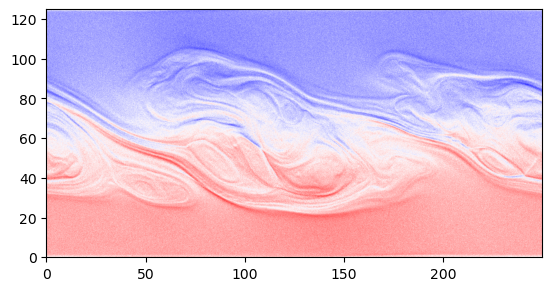

In [47]:
fig, ax = plt.subplots()
ax.imshow(ds['ue'].sel(c = 'y'), extent = (ds.y[0], ds.y[-1], ds.x[0], ds.x[-1]), cmap='bwr')

In [52]:
from turbos.filter import kfilter
Pe = kfilter(ds['Pe'], 5)
ue = kfilter(ds['ue'], 5)

# print(Pi)
from turbos.pressure_strain import pressure_strain

pse = pressure_strain(Pe, ue)
print(pse)
print(np.average(pse['PiD']))

<xarray.Dataset> Size: 35MB
Dimensions:  (x: 1200, y: 2400)
Coordinates:
  * x        (x) float64 10kB 0.0 0.1042 0.2083 0.3125 ... 124.7 124.8 124.9
  * y        (y) float64 19kB 0.0 0.1042 0.2083 0.3125 ... 249.7 249.8 249.9
    j        <U1 4B 'z'
    i        <U1 4B 'z'
    c        <U1 4B 'x'
Data variables:
    pth      (x, y) float32 12MB 3.996e-05 4.66e-05 ... 1.136e-05 1.983e-05
    PiD      (x, y) float64 23MB 8.833e-06 7.878e-06 ... 8.081e-06 8.43e-06
1.2439265429024305e-07


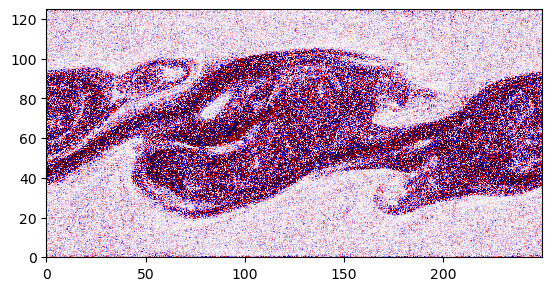

In [53]:
fig, ax = plt.subplots()
vmag = 2e-5
ax.imshow(pse['PiD'], interpolation='nearest', cmap='seismic', origin='lower', extent = (ds.y[0], ds.y[-1], ds.x[0], ds.x[-1]), vmin = -vmag, vmax = vmag)